# Pipeline walkthrough: one coffin run, from manifest to label

This notebook follows a single candidate run of the PAHMA 5-613 coffin, **`side40_s1`**, through
the scoring pipeline against its full-capture reference **`ref145b`**. It uses saved data only:
manifests, `cameras.csv` files and the two raw meshes written by Metashape. Nothing is
reconstructed here. Steps 3–5 rerun the scorer in `src/bd3d_quality/evaluation.py`, and step 6
checks that the result equals the stored label in `results/pahma-5-613-v2/labels-all.csv`.

| step | input | output |
|---|---|---|
| 1 | candidate + parent manifests | which photos were used / removed |
| 2 | `cameras.csv` of both runs | camera layout, removed cameras |
| 3 | cameras + meshes | similarity transform, ICP refinement |
| 4 | aligned meshes | missing and extra surface distances |
| 5 | distances | v3 label |
| 6 | label | exact match with `labels-all.csv` |

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from IPython.display import display, Markdown

from bd3d_quality import evaluation as ev
from bd3d_quality.manifests import experiment_identity
from bd3d_quality.provenance import sha256_file

REPO = Path('..').resolve()  # repository root, relative to this notebook
RUNS = REPO / 'results' / 'pahma-5-613-v2'
REF, CAND = RUNS / 'ref145b', RUNS / 'side40_s1'
EXP = REPO / 'experiments' / 'pahma-5-613'
LABELS = RUNS / 'labels-all.csv'
SCORES = RUNS / 'geometry-v3-all'
pd.set_option('display.float_format', lambda v: f'{v:.6g}')
for p in [EXP / 'parent-145.json', EXP / 'candidates/side40_s1.json', REF / 'cameras.csv', CAND / 'cameras.csv',
          REF / 'raw-mesh.obj', CAND / 'raw-mesh.obj', LABELS, SCORES / 'settings.json']:
    print(f'{str(p.relative_to(REPO)):55s} {"found" if p.exists() else "MISSING"}')
missing = [p for p in (REF / 'raw-mesh.obj', CAND / 'raw-mesh.obj') if not p.exists()]
if missing:
    raise FileNotFoundError('raw meshes are local-only (not in git); steps 3-6 need: '
                            + ', '.join(str(p.relative_to(REPO)) for p in missing))

experiments/pahma-5-613/parent-145.json                 found
experiments/pahma-5-613/candidates/side40_s1.json       found
results/pahma-5-613-v2/ref145b/cameras.csv              found
results/pahma-5-613-v2/side40_s1/cameras.csv            found
results/pahma-5-613-v2/ref145b/raw-mesh.obj             found
results/pahma-5-613-v2/side40_s1/raw-mesh.obj           found
results/pahma-5-613-v2/labels-all.csv                   found
results/pahma-5-613-v2/geometry-v3-all/settings.json    found


## 1. The manifest: which photos were used

Every run starts from a manifest: an ordered list of images with their SHA-256 and size, plus the
reconstruction settings. The experiment ID is a hash of exactly those fields, so two runs with the
same ID used the same photos and settings. `side40_s1` was made from the 145-image parent manifest
by removing one contiguous azimuth sector of the wall-level series (series 1). The manifest records
the rule and the removed indices.

In [ ]:
parent = json.loads((EXP / 'parent-145.json').read_text())
cand_m = json.loads((EXP / 'candidates' / 'side40_s1.json').read_text())
sel = cand_m['selection']
print('parent  ', parent['experiment_id'], f"({parent['image_count']} images)")
print('candidate', cand_m['experiment_id'], f"({cand_m['image_count']} images)")
print('IDs recompute from the manifest contents:',
      experiment_identity(parent) == parent['experiment_id'], experiment_identity(cand_m) == cand_m['experiment_id'])
print('candidate points at this parent:', sel['parent_experiment_id'] == parent['experiment_id'])
print('strategy:', sel['strategy']); print('rule:    ', sel['rule'])

par_imgs = [e['path'] for e in parent['images']]
kept = [par_imgs[i] for i in sel['indices_zero_based']]
removed = [par_imgs[i] for i in sel['removed_indices_zero_based']]
assert kept == [e['path'] for e in cand_m['images']], 'kept indices disagree with the image list'
assert sorted(sel['indices_zero_based'] + sel['removed_indices_zero_based']) == list(range(len(par_imgs)))
same_hash = all(a == b for a, b in zip((parent['images'][i] for i in sel['indices_zero_based']), cand_m['images']))
print(f'{len(kept)} used + {len(removed)} removed = {len(par_imgs)}; kept entries identical to parent (hash, size): {same_hash}')
display(Markdown('**Removed photos:** ' + ', '.join(f'`{p}`' for p in removed)))

parent   bd3d-a118b4ce72d7d322351c4edd3cbf55877b070448b531da92c97cbada3f8570c6 (145 images)
candidate bd3d-c731ef62f1479d9341c8644044a3fd7e6f2df9a309dfa4cc93031140dde67e8d (122 images)
IDs recompute from the manifest contents: True True
candidate points at this parent: True
strategy: series1_contiguous_side_removed
rule:     series-1 cameras sorted by azimuth; 23 of 57 consecutive removed from sorted position 17 (azimuth 95.3..219.3 deg in reference pose frame)
122 used + 23 removed = 145; kept entries identical to parent (hash, size): True


**Removed photos:** `_MG_4748.jpg`, `_MG_4749.jpg`, `_MG_4750.jpg`, `_MG_4751.jpg`, `_MG_4752.jpg`, `_MG_4753.jpg`, `_MG_4754.jpg`, `_MG_4755.jpg`, `_MG_4756.jpg`, `_MG_4757.jpg`, `_MG_4758.jpg`, `_MG_4759.jpg`, `_MG_4760.jpg`, `_MG_4761.jpg`, `_MG_4762.jpg`, `_MG_4797.jpg`, `_MG_4798.jpg`, `_MG_4799.jpg`, `_MG_4800.jpg`, `_MG_4801.jpg`, `_MG_4802.jpg`, `_MG_4803.jpg`, `_MG_4804.jpg`

## 2. `cameras.csv`: the aligned camera layout

After alignment, each run writes one row per camera: position (`x, y, z`) and view direction
(`view_x, view_y, view_z`) in that run's own Metashape frame, plus reprojection error. These rows are
the model input. Below, the **reference** cameras are drawn top-down: the up axis is the direction in
which camera positions spread least, and the centre is the point closest to all viewing rays (the same
frame as `docs/figures/hero.png`). The 23 cameras removed for `side40_s1` are highlighted; they form one
contiguous sector of the lowest ring. The azimuth origin is arbitrary (it depends on the frame
construction), so the sector's degree range here is offset from the one quoted in the manifest's rule,
which comes from `series_split_from_poses.py`; its width and the cameras in it are the same.

reference: 145 aligned cameras; candidate: 122 aligned cameras
candidate labels = reference labels minus removed: True


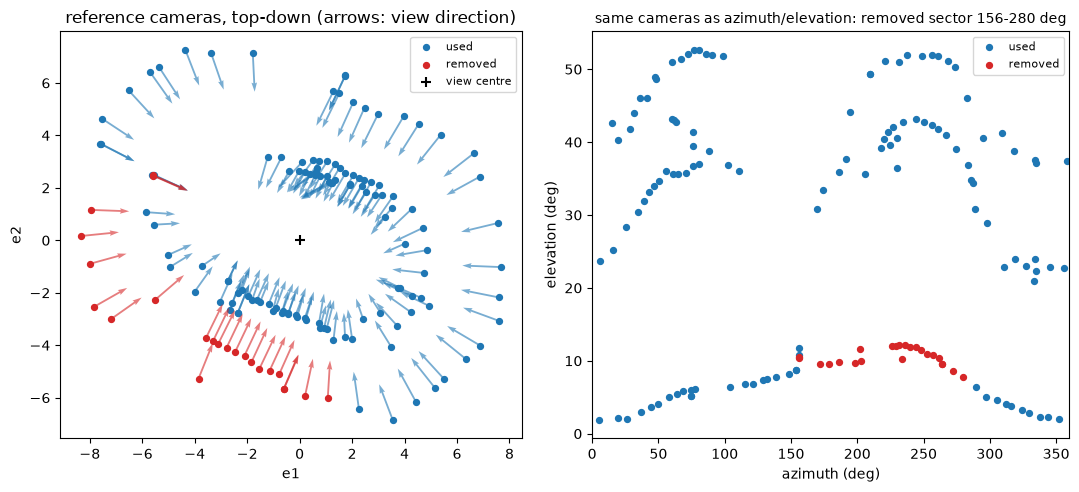

In [ ]:
def read_cams(path):
    c = pd.read_csv(path)
    return c[c['aligned'].astype(str) == 'True'].reset_index(drop=True)

def up_frame(P, V):
    # centre = least-squares point nearest all viewing rays; up = least-spread direction of the cameras
    A, b = np.zeros((3, 3)), np.zeros(3)
    for p, v in zip(P, V):
        M = np.eye(3) - np.outer(v, v); A += M; b += M @ p
    c = np.linalg.solve(A, b)
    D = P - c; D /= np.linalg.norm(D, axis=1, keepdims=True)
    up = np.linalg.eigh(np.cov(D.T))[1][:, 0]
    up = up if (D @ up).mean() > 0 else -up
    e1 = np.linalg.svd(np.eye(3) - np.outer(up, up))[0][:, 0]
    return c, np.stack([e1, np.cross(up, e1), up])  # rows: e1, e2, up

ref_c, cand_c = read_cams(REF / 'cameras.csv'), read_cams(CAND / 'cameras.csv')
P_ref, V_ref = ref_c[['x', 'y', 'z']].to_numpy(), ref_c[['view_x', 'view_y', 'view_z']].to_numpy()
centre, B = up_frame(P_ref, V_ref)
top = lambda X: (X - centre) @ B.T          # reference frame -> (e1, e2, up)
removed_stems = {Path(p).stem for p in removed}
is_removed = ref_c['label'].isin(removed_stems).to_numpy()
print(f'reference: {len(ref_c)} aligned cameras; candidate: {len(cand_c)} aligned cameras')
print('candidate labels = reference labels minus removed:', set(cand_c['label']) == set(ref_c['label']) - removed_stems)

Q, W = top(P_ref), V_ref @ B.T
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
for m, kw in [(~is_removed, dict(color='tab:blue', label='used')), (is_removed, dict(color='tab:red', label='removed'))]:
    ax.quiver(Q[m, 0], Q[m, 1], W[m, 0], W[m, 1], angles='xy', scale=12, width=0.004, alpha=0.6, color=kw['color'])
    ax.scatter(Q[m, 0], Q[m, 1], s=18, **kw)
ax.scatter([0], [0], marker='+', color='k', s=60, label='view centre')
ax.set_aspect('equal'); ax.set_title('reference cameras, top-down (arrows: view direction)')
ax.set_xlabel('e1'); ax.set_ylabel('e2'); ax.legend(fontsize=8)
ax = axes[1]
az = np.degrees(np.arctan2(Q[:, 1], Q[:, 0])) % 360
el = np.degrees(np.arcsin(np.clip(Q[:, 2] / np.linalg.norm(Q, axis=1), -1, 1)))
ax.scatter(az[~is_removed], el[~is_removed], s=18, color='tab:blue', label='used')
ax.scatter(az[is_removed], el[is_removed], s=18, color='tab:red', label='removed')
ax.set_xlim(0, 360); ax.set_xlabel('azimuth (deg)'); ax.set_ylabel('elevation (deg)')
ax.set_title(f'same cameras as azimuth/elevation: removed sector {az[is_removed].min():.0f}-{az[is_removed].max():.0f} deg', fontsize=10)
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

## 3. Registration: camera similarity fit, then ICP

Metashape places each run in its own arbitrary frame (no markers), so the candidate mesh must first be
brought into the reference frame. Evaluator v3 does this in two stages:

1. **Camera similarity fit.** `camera_transform` solves for the rotation, translation and uniform scale
   that best map the candidate's camera centres onto the reference camera centres of the *same images*
   (Umeyama least squares). This needs no mesh at all and cannot fall into a wrong local minimum.
2. **ICP refinement.** `icp` starts from that transform and runs point-to-point ICP on 20,000 surface
   samples per mesh, re-solving rotation, translation and uniform scale each iteration, with
   correspondences limited to 5% of the reference bounding-box diagonal.

Before scoring, the two meshes are checked against the SHA-256 values recorded when the labels were made.

In [ ]:
s = ev.SETTINGS
row = pd.read_csv(LABELS).set_index('run').loc['side40_s1']
settings = json.loads((SCORES / 'settings.json').read_text())
print('reference mesh sha256 matches settings.json: ', sha256_file(REF / 'raw-mesh.obj') == settings['reference_mesh_sha256'])
print('candidate mesh sha256 matches labels-all.csv:', sha256_file(CAND / 'raw-mesh.obj') == row['candidate_mesh_sha256'])
print('evaluator settings signature matches:        ', ev.v3_settings()['signature'] == settings['evaluator_v3']['signature'])

ref = ev.Reference.from_files(REF / 'raw-mesh.obj', REF / 'cameras.csv')
cand_mesh = ev.load_obj_mesh(CAND / 'raw-mesh.obj')
cand_cams = ev.load_cameras(CAND / 'cameras.csv')
reg_cand = ev.sample_surface(cand_mesh, s.registration_sample_count, s.random_seed)
eval_cand = ev.sample_surface(cand_mesh, s.evaluation_sample_count, s.random_seed + 1)
print(f'reference: {len(ref.mesh.vertices):,} vertices, bbox diagonal {ref.diag:.4f}; '
      f'candidate: {len(cand_mesh.vertices):,} vertices')

# stage 1: cameras only
T0, n_shared, resid = ev.camera_transform(cand_cams, ref.cameras)
init_d, _ = cKDTree(ref.reg_pts).query(ev.apply_transform(reg_cand, T0), workers=1)
# stage 2: similarity ICP from T0 (the transform the label uses)
sim = ev.icp(reg_cand, ref.reg_pts, T0, ref.cutoff, s.icp_max_iterations, s.icp_relative_tolerance,
             s.icp_absolute_tolerance_fraction * ref.diag, with_scale=True)
T = sim['transform']
cam_scale = ev.scale_of(T0); ratio = sim['scale'] / cam_scale
R0, R1 = T0[:3, :3] / cam_scale, T[:3, :3] / sim['scale']
step_deg = np.degrees(np.arccos(np.clip((np.trace(R1 @ R0.T) - 1) / 2, -1, 1)))
display(pd.DataFrame([
    ('shared images used for the camera fit', n_shared),
    ('camera fit residual / reference camera spread', resid),
    ('camera scale (candidate -> reference)', cam_scale),
    ('fitness at camera init (share of samples within cutoff)', float((init_d <= ref.cutoff).mean())),
    ('ICP iterations / converged', f"{sim['iterations']} / {sim['converged']}"),
    ('ICP scale', sim['scale']),
    ('ICP scale / camera scale (flag if off by > 2.5%)', ratio),
    ('rotation changed by ICP (deg)', step_deg),
    ('fitness after ICP', sim['fitness']),
    ('QC', ev.qc(sim['fitness'])),
], columns=['quantity', 'value']).set_index('quantity'))

reference mesh sha256 matches settings.json:  True
candidate mesh sha256 matches labels-all.csv: True
evaluator settings signature matches:         True


reference: 134,178 vertices, bbox diagonal 8.7167; candidate: 115,944 vertices


,value
quantity,
shared images used for the camera fit,122
camera fit residual / reference camera spread,0.000905034
camera scale (candidate -> reference),1.30514
fitness at camera init (share of samples within cutoff),1
ICP iterations / converged,32 / True
ICP scale,1.30701
ICP scale / camera scale (flag if off by > 2.5%),1.00143
rotation changed by ICP (deg),0.178507
fitness after ICP,1


The views below show 4,000 surface samples of each mesh, projected into the reference top-down frame
from step 2 (top row) and a side view (bottom row). Left: the candidate in its own Metashape frame,
untouched. Middle: after the camera similarity fit alone. Right: after ICP. Most of the alignment comes from
the cameras; ICP makes a small final correction.

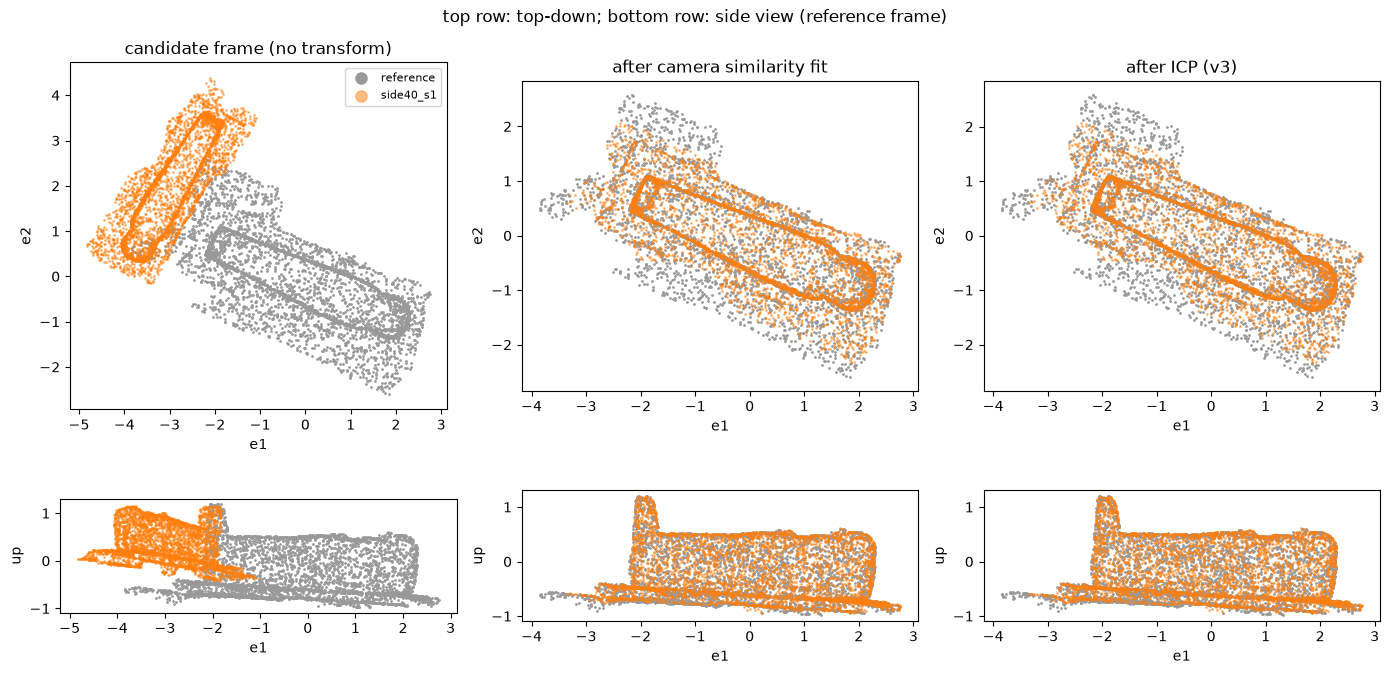

In [ ]:
rng = np.random.default_rng(0)
ri = rng.choice(len(ref.reg_pts), 4000, replace=False); ci = rng.choice(len(reg_cand), 4000, replace=False)
views = [('candidate frame (no transform)', np.eye(4)), ('after camera similarity fit', T0), ('after ICP (v3)', T)]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for j, (title, M) in enumerate(views):
    R_, C_ = top(ref.reg_pts[ri]), top(ev.apply_transform(reg_cand[ci], M))
    for i, (a, b, lab) in enumerate([(0, 1, ('e1', 'e2')), (0, 2, ('e1', 'up'))]):
        ax = axes[i, j]
        ax.scatter(R_[:, a], R_[:, b], s=1, color='0.6', label='reference')
        ax.scatter(C_[:, a], C_[:, b], s=1, color='tab:orange', alpha=0.5, label='side40_s1')
        ax.set_aspect('equal'); ax.set_xlabel(lab[0]); ax.set_ylabel(lab[1])
        if i == 0: ax.set_title(title)
axes[0, 0].legend(markerscale=8, fontsize=8)
fig.suptitle('top row: top-down; bottom row: side view (reference frame)'); fig.tight_layout(); plt.show()

## 4. Missing and extra surface

With the candidate aligned, 100,000 area-weighted samples are drawn from each mesh and every sample is matched
to its nearest neighbour on the other mesh:

- **Missing surface: reference → candidate.** For each reference sample, the distance to the nearest
  candidate sample. Large where the reference has surface the candidate did not reconstruct.
- **Extra surface: candidate → reference.** For each candidate sample, the distance to the nearest
  reference sample. Large where the candidate has surface with no counterpart in the reference (noise or
  misplaced parts).

Distances are divided by the reference bounding-box diagonal. The dashed line is the 5% cutoff used by ICP.

,RMSE,median,p95,max,share > cutoff
missing (ref -> cand),0.0112343,0.00110661,0.0276036,0.0809183,0.01678
extra (cand -> ref),0.00149533,0.00106469,0.0025012,0.0139267,0


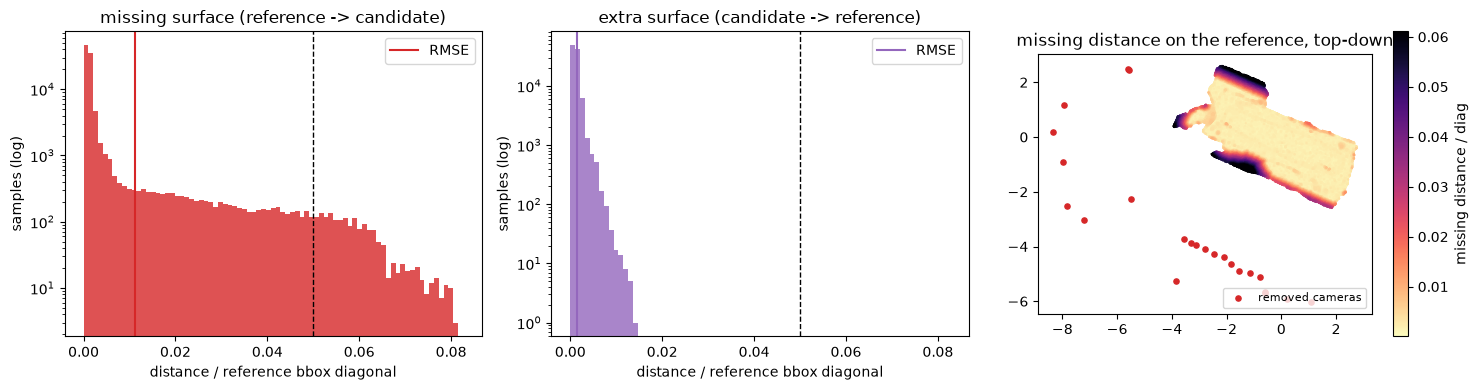

In [ ]:
cand_eval_T = ev.apply_transform(eval_cand, T)
c2r, _ = cKDTree(ref.eval_pts).query(cand_eval_T, workers=1)   # extra surface
r2c, _ = cKDTree(cand_eval_T).query(ref.eval_pts, workers=1)   # missing surface
miss, extra = r2c / ref.diag, c2r / ref.diag
summary = pd.DataFrame({k: {'RMSE': np.sqrt(np.mean(v ** 2)), 'median': np.median(v), 'p95': np.percentile(v, 95),
                            'max': v.max(), 'share > cutoff': np.mean(v > 0.05)}
                        for k, v in [('missing (ref -> cand)', miss), ('extra (cand -> ref)', extra)]}).T
display(summary)

bins = np.linspace(0, max(miss.max(), extra.max()) * 1.02, 80)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, v, name, col in [(axes[0], miss, 'missing surface (reference -> candidate)', 'tab:red'),
                         (axes[1], extra, 'extra surface (candidate -> reference)', 'tab:purple')]:
    ax.hist(v, bins=bins, color=col, alpha=0.8); ax.set_yscale('log')
    ax.axvline(0.05, ls='--', color='k', lw=1); ax.axvline(np.sqrt(np.mean(v ** 2)), color=col, lw=1.5, label='RMSE')
    ax.set_xlabel('distance / reference bbox diagonal'); ax.set_ylabel('samples (log)'); ax.set_title(name); ax.legend()
P = top(ref.eval_pts)
o = np.argsort(miss)
sc = axes[2].scatter(P[o, 0], P[o, 1], c=miss[o], s=0.3, cmap='magma_r', vmax=np.percentile(miss, 99.5))
axes[2].scatter(Q[is_removed, 0], Q[is_removed, 1], s=14, color='tab:red', label='removed cameras')
axes[2].set_aspect('equal'); axes[2].set_title('missing distance on the reference, top-down')
axes[2].legend(fontsize=8, loc='lower right'); fig.colorbar(sc, ax=axes[2], label='missing distance / diag')
fig.tight_layout(); plt.show()

## 5. From distances to the v3 label

The label is the symmetric RMSE: the root of the mean of the two mean-squared distances, divided by the
reference bounding-box diagonal,

$$\text{label}_{v3} = \frac{1}{d}\sqrt{\tfrac12\left(\overline{c2r^2} + \overline{r2c^2}\right)}
= \sqrt{\tfrac12\left(\text{extra}^2 + \text{missing}^2\right)}$$

where *missing* and *extra* are the normalized RMSEs from step 4. `combine_labels.py` adds two
summaries of the split: which side dominates, and the missing share of the squared error. A label of
0.01 means an RMSE of 1% of the object's diagonal.

missing RMSE / diag = 0.011234
extra   RMSE / diag = 0.001495
label_v3            = 0.008014   (from the two parts: 0.008014)
dominant error      = missing; missing share of squared error = 0.983


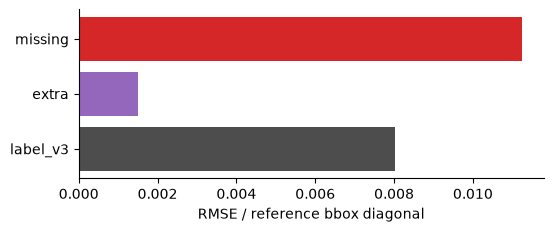

In [ ]:
m_rmse, e_rmse = np.sqrt(np.mean(miss ** 2)), np.sqrt(np.mean(extra ** 2))
label = float(np.sqrt((np.mean(c2r ** 2) + np.mean(r2c ** 2)) / 2) / ref.diag)
from_parts = np.sqrt((m_rmse ** 2 + e_rmse ** 2) / 2)
share = m_rmse ** 2 / (m_rmse ** 2 + e_rmse ** 2)
print(f'missing RMSE / diag = {m_rmse:.6f}')
print(f'extra   RMSE / diag = {e_rmse:.6f}')
print(f'label_v3            = {label:.6f}   (from the two parts: {from_parts:.6f})')
print(f"dominant error      = {'missing' if m_rmse > e_rmse else 'extra'}; missing share of squared error = {share:.3f}")
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(['label_v3', 'extra', 'missing'], [label, e_rmse, m_rmse], color=['0.3', 'tab:purple', 'tab:red'])
ax.set_xlabel('RMSE / reference bbox diagonal'); ax.spines[['top', 'right']].set_visible(False); plt.show()

## 6. Check against the stored label

The values recomputed above are compared with the stored row for `side40_s1` in
`results/pahma-5-613-v2/labels-all.csv`, which `score_runs_v3.py` and `combine_labels.py` wrote.
Comparison is exact (`==` on the floats as stored), not within a tolerance. The whole-function path,
`score_candidate`, is run too and must agree with the step-by-step values.

In [ ]:
m = ev.surface_distances(ref.eval_pts, eval_cand, T, ref.diag, ref.cutoff, s)
full, _ = ev.score_candidate(ref, cand_mesh, cand_cams)
computed = {
    'label_v3': label, 'qc_v3': ev.qc(sim['fitness']), 'fitness_v3': sim['fitness'],
    'scale_check': 'agree' if abs(ratio - 1) <= ev.SCALE_TOLERANCE else 'disagree',
    'missing_surface_rmse_norm': m['r2c_rmse_norm'], 'missing_surface_p95_norm': m['r2c_p95_norm'],
    'missing_surface_frac_beyond_cutoff': m['r2c_frac_beyond_cutoff'],
    'extra_surface_rmse_norm': m['c2r_rmse_norm'], 'extra_surface_p95_norm': m['c2r_p95_norm'],
    'extra_surface_frac_beyond_cutoff': m['c2r_frac_beyond_cutoff'],
    'completeness_at_0.01': m['completeness_at_0.01'], 'accuracy_at_0.01': m['accuracy_at_0.01'],
    'dominant_error': 'missing' if m['r2c_rmse_norm'] > m['c2r_rmse_norm'] else 'extra',
    'missing_share_of_sq_error': m['r2c_rmse_norm'] ** 2 / (m['r2c_rmse_norm'] ** 2 + m['c2r_rmse_norm'] ** 2),
}
check = pd.DataFrame([(k, row[k], v, row[k] == v) for k, v in computed.items()],
                     columns=['column', 'labels-all.csv', 'recomputed', 'exact match']).set_index('column')
display(check)
assert m['y'] == label, 'step-by-step label differs from surface_distances'
assert full['label_v3'] == label, 'score_candidate differs from the step-by-step label'
assert check['exact match'].all(), 'recomputed values differ from labels-all.csv'
print(f"All {len(check)} columns match labels-all.csv exactly; label_v3 = {float(row['label_v3'])!r}")

,labels-all.csv,recomputed,exact match
column,,,
label_v3,0.00801394,0.00801394,True
qc_v3,pass,pass,True
fitness_v3,1,1,True
scale_check,agree,agree,True
missing_surface_rmse_norm,0.0112343,0.0112343,True
missing_surface_p95_norm,0.0276036,0.0276036,True
missing_surface_frac_beyond_cutoff,0.01678,0.01678,True
extra_surface_rmse_norm,0.00149533,0.00149533,True
extra_surface_p95_norm,0.0025012,0.0025012,True


All 14 columns match labels-all.csv exactly; label_v3 = 0.008013937109164796
